# 07 · BM25 dari token sampai ranking

**Tujuan:** Membuktikan skor BM25 dari perhitungan token, frekuensi dokumen, IDF, dan normalisasi panjang dokumen.

**Alur:** input → proses yang terlihat → pengecekan → output. Semua label kompetensi lama hanya dipakai sebagai referensi audit, bukan kebenaran relevansi.

## 0. Setup dan validasi sumber data

In [1]:
from pathlib import Path
import os, sys, json, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT/'data'/'dataset_buku_2000.csv').exists(): ROOT=ROOT.parent
assert (ROOT/'data'/'dataset_buku_2000.csv').exists(), f'Folder proyek tidak ditemukan dari {Path.cwd()}'
sys.path.insert(0,str(ROOT))
from src import engine
DATA, OUT, FIG, MODELS = [ROOT/x for x in ('data','outputs','figures','models')]
for folder in (OUT,FIG,MODELS): folder.mkdir(exist_ok=True)
books, comps = engine.load_data()
print('Dataset:',len(books),'buku;',len(comps),'kompetensi')
assert books.book_id.is_unique and comps.competency_id.is_unique

Dataset: 973 buku; 67 kompetensi


## 1. Memuat keluaran preprocessing dan profil kompetensi

Input yang sama dipakai pada lima model; label kompetensi awal tidak dipakai untuk menyaring buku.

In [2]:
clean=pd.read_csv(OUT/'dataset_buku_bersih.csv',dtype=str).fillna('')
profiles=pd.read_csv(OUT/'profil_kompetensi_query.csv',dtype=str).fillna('')
assert len(clean)==len(books) and len(profiles)==len(comps)
books['teks_buku']=clean.set_index('book_id').reindex(books.book_id)['teks_model'].fillna('').to_numpy() if 'teks_model' in clean.columns else books.teks_buku
comps['teks_query']=profiles.set_index('competency_id').reindex(comps.competency_id)['teks_query'].fillna('').to_numpy() if 'teks_query' in profiles.columns else comps.teks_query
assert books.teks_buku.str.len().gt(0).all()
print('Contoh buku:',books[['judul','teks_buku']].head(2).to_string(index=False,max_colwidth=110))
print('Contoh kompetensi:',comps[['competency_name','teks_query']].head(2).to_string(index=False,max_colwidth=110))

Contoh buku:                                judul                                                                                                      teks_buku
            Business Growth Strategy Business Growth Strategy Business Growth Strategy Introduction I wrote this book, “Business Growth Strategy...
Mastering Business Growth Strategies Mastering Business Growth Strategies Mastering Business Growth Strategies Mastering Business Growth Strateg...
Contoh kompetensi:      competency_name                                                                          teks_query
Business Development       Business Development business growth; business strategy; market opportunities
Marketing Management Marketing Management marketing strategy; marketing analytics; customer segmentation


## 2. Melihat tokenisasi dan frekuensi dokumen

Tahap ini memperlihatkan istilah yang benar-benar cocok, bukan hanya memanggil fungsi model.

In [3]:
from collections import Counter
corpus=[engine.tok(t) for t in books.teks_buku]
df=Counter()
for tokens in corpus: df.update(set(tokens))
query_tokens=engine.tok(comps.teks_query.iloc[0])
print('Query:',comps.competency_name.iloc[0], '\nToken:',query_tokens)
print('Token buku pertama:',corpus[0][:25])
print('Document frequency query:',{t:df[t] for t in set(query_tokens)})

Query: Business Development 
Token: ['business', 'development', 'business', 'growth', 'business', 'strategy', 'market', 'opportunities']
Token buku pertama: ['business', 'growth', 'strategy', 'business', 'growth', 'strategy', 'introduction', 'wrote', 'book', 'business', 'growth', 'strategy', 'help', 'entrepreneurs', 'learn', 'how', 'grow', 'their', 'business', 'use', 'best', 'strategies', 'you', 'read', 'book']
Document frequency query: {'strategy': 86, 'opportunities': 44, 'market': 72, 'business': 563, 'growth': 45, 'development': 197}


## 3. Perhitungan BM25 manual pada satu buku

Nilai 0 berarti istilah query tidak ditemukan pada buku tersebut.

In [4]:
from collections import Counter
N=len(books); k1=1.5; b=0.75
avgdl=np.mean([len(t) for t in corpus]);j=0
freq=Counter(corpus[j]);manual=[]
for t in sorted(set(query_tokens)):
    idf=np.log(1+(N-df[t]+0.5)/(df[t]+0.5))
    tf=freq[t]
    contribution=idf*tf*(k1+1)/(tf+k1*(1-b+b*len(corpus[j])/avgdl)) if tf else 0
    manual.append([t,tf,df[t],round(idf,4),round(contribution,4)])
display(pd.DataFrame(manual,columns=['token','tf_buku','df_katalog','idf','kontribusi_bm25']))
print('Jumlah skor manual buku ke-1:',round(sum(x[-1] for x in manual),4))

,token,tf_buku,df_katalog,idf,kontribusi_bm25
0,business,17,563,0.5472,1.1424
1,development,0,197,1.5957,0.0000
2,growth,18,45,3.0637,6.4550
3,market,2,72,2.5978,2.4242
4,opportunities,1,44,3.0859,1.7702
5,strategy,8,86,2.4213,4.2635


Jumlah skor manual buku ke-1: 16.0553


## 4. Menghitung seluruh 67 × 973 pasangan dan mengukur waktu

Skor seluruh buku dihitung tanpa membatasi label kompetensi lama.

In [5]:
start=time.perf_counter()
scores, detail=engine.matrix_bm25(books,comps)
elapsed=time.perf_counter()-start
print('Matrix',scores.shape,'range',scores.min(),scores.max(),'durasi (detik)',round(elapsed,2))
assert scores.shape==(len(comps),len(books))
print('Verifikasi skor manual vs engine:',round(scores[0,0],4))
assert np.isclose(scores[0,0],sum(x[-1] for x in manual),atol=.002)

Matrix (67, 973) range 0.0 25.667923473075273 durasi (detik) 0.27
Verifikasi skor manual vs engine: 16.0554


## 5. Audit ranking, penyimpanan, dan visualisasi

Hasil tersimpan di outputs/skor_semua_pasangan_bm25.csv dan outputs/top10_bm25.csv.

,ranking,judul,skor_asli
0,1,Emerging Business Opportunities in Africa: Mar...,16.246092
1,2,Mastering Business Strategy,16.172456
2,3,Business Growth Strategy,16.055411
3,4,Mastering Business Growth Strategies,14.401057
4,5,Business Development For Dummies,13.944784
5,6,Developing a market expansion strategy of a UK...,13.446291
6,7,Strategic Internet Business Management - an As...,13.282931
7,8,The Art of Creative Product Strategy,12.967332
8,9,Analysis of growth strategies. Organic vs. ino...,12.226061
9,10,"Innovation, Product Development and Commercial...",11.584966


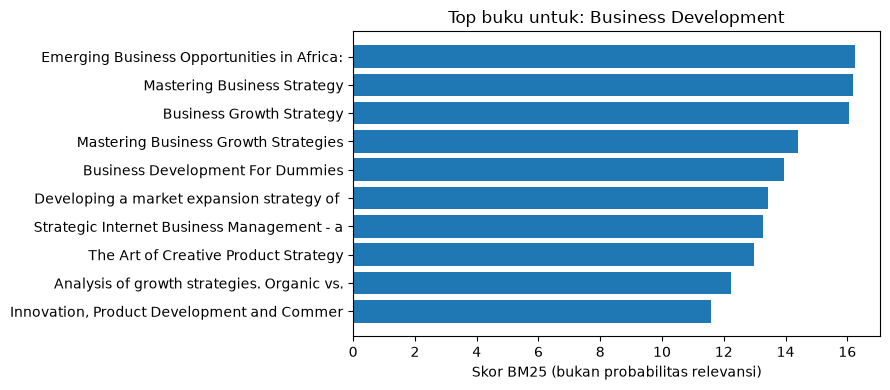

In [6]:
pairs,top=engine.save_all_pairs(scores,books,comps,'bm25')
pd.DataFrame([{'model':'bm25','waktu_total_detik':elapsed,'jumlah_pasangan':len(pairs)}]).to_csv(OUT/'runtime_bm25.csv',index=False)
q=top[top.competency_id==comps.competency_id.iloc[0]]
display(q[['ranking','judul','skor_asli']].head(10))
fig,ax=plt.subplots(figsize=(9,4));ax.barh(q.judul.str.slice(0,42).iloc[::-1],q.skor_asli.iloc[::-1]);ax.set_xlabel('Skor BM25 (bukan probabilitas relevansi)');ax.set_title('Top buku untuk: '+comps.competency_name.iloc[0]);plt.tight_layout();fig.savefig(FIG/'07_bm25_top10.png',dpi=130);plt.show()
assert len(pairs)==len(books)*len(comps)

## Kesimpulan tahap dan serah-terima

Periksa tabel/grafik yang tercetak, simpan artefak hasil, lalu lanjut ke notebook berikutnya. **Kesamaan kata, similarity dan percentile bukan ground truth relevansi.** Jangan mengklaim metrik akurasi tanpa penilaian independen.